## 1. Import Thư viện
Sử dụng các thư viện cần thiết cho quá trình xây dựng mô hình Hồi quy tuyến tính đa biến. Pandas và NumPy hỗ trợ xử lý dữ liệu, Matplotlib dùng để trực quan hóa, còn Scikit-learn cung cấp các công cụ tiền xử lý, huấn luyện và đánh giá mô hình.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.dummy import DummyRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

## 2. Đọc dữ liệu dùng chung
Đọc bộ dữ liệu giao thông đã được làm sạch từ file cleaned_traffic.csv. Chuyển cột date_time sang định dạng thời gian, đồng thời tạo các thư mục để lưu bảng kết quả và biểu đồ. Kiểm tra kích thước và một số dòng dữ liệu ban đầu

In [4]:
# Tim thu muc du an va file du lieu
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Tao cac thu muc luu ket qua
OUT = ROOT / "outputs"
OUT_03 = OUT / "03_Multiple_Linear_Regression"
TABLE_DIR = OUT_03 / "tables"
FIG = OUT_03 / "figures"
INPUT_FILE = OUT / "cleaned_traffic.csv"

FIG.mkdir(parents=True, exist_ok=True)
OUT_03.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Doc du lieu
model_df = pd.read_csv(INPUT_FILE)
model_df["date_time"] = pd.to_datetime(
    model_df["date_time"],
    errors="coerce"
)

print("File du lieu:", INPUT_FILE.resolve())
print("Thu muc ket qua:", TABLE_DIR.resolve())
print("Kich thuoc du lieu:", model_df.shape)

display(model_df.head())

File du lieu: C:\Users\PHUONG NHI\Downloads\524H0185_524H0073_524H0175\outputs\cleaned_traffic.csv
Thu muc ket qua: C:\Users\PHUONG NHI\Downloads\524H0185_524H0073_524H0175\outputs\03_Multiple_Linear_Regression\tables
Kich thuoc du lieu: (40575, 17)


,date_time,temp,rain_1h,snow_1h,clouds_all,traffic_volume,weather_main,holiday,weather_description,hour,day_of_week,month,year,is_weekend,temp_c,is_holiday,time_period
0,2012-10-02 09:00:00,288.28,0.0,0.0,40.0,5545,Clouds,NaN,scattered clouds,9,1,10,2012,0,15.13,0,Sang (6-11)
1,2012-10-02 10:00:00,289.36,0.0,0.0,75.0,4516,Clouds,NaN,broken clouds,10,1,10,2012,0,16.21,0,Sang (6-11)
2,2012-10-02 11:00:00,289.58,0.0,0.0,90.0,4767,Clouds,NaN,overcast clouds,11,1,10,2012,0,16.43,0,Sang (6-11)
3,2012-10-02 12:00:00,290.13,0.0,0.0,90.0,5026,Clouds,NaN,overcast clouds,12,1,10,2012,0,16.98,0,Chieu (12-17)
4,2012-10-02 13:00:00,291.14,0.0,0.0,75.0,4918,Clouds,NaN,broken clouds,13,1,10,2012,0,17.99,0,Chieu (12-17)


## 3. Làm sạch tối thiểu cho mô hình
Xác định các biến đầu vào gồm nhiệt độ, lượng mưa, tuyết, độ che phủ mây và các đặc trưng về thời gian, ngày lễ, thời tiết. Biến mục tiêu là traffic_volume.

Kiểm tra các cột bắt buộc, chuyển dữ liệu số về đúng định dạng, loại bỏ những dòng thiếu thời gian hoặc giá trị mục tiêu không hợp lệ. Sau đó, tạo các đặc trưng giờ, thứ trong tuần và tháng từ date_time, rồi kiểm tra dữ liệu thiếu và thời gian quan sát.

In [5]:
# Cac bien so dau vao
numeric_features = [
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all"
]

# Cac bien phan loai
categorical_features = [
    "hour",
    "day_of_week",
    "month",
    "holiday",
    "weather_main"
]

target = "traffic_volume"

# Kiem tra cac cot co san trong dataset goc truoc khi tao dac trung thoi gian
required_columns = [
    "date_time", target, *numeric_features, "holiday", "weather_main"
]
missing_columns = [col for col in required_columns if col not in model_df.columns]

if missing_columns:
    raise ValueError(f"Thiếu các cột cần thiết: {missing_columns}")

# Chuyển biến số về dạng số; giá trị không hợp lệ được chuyển thành NaN
for col in numeric_features + [target]:
    model_df[col] = pd.to_numeric(model_df[col], errors="coerce")

model_df[numeric_features + [target]] = (
    model_df[numeric_features + [target]].replace([np.inf, -np.inf], np.nan)
)

#  Khong the huan luyen neu thieu thoi gian hoac target  
model_df = model_df.dropna(subset=["date_time", target]).copy()
# Kiem tra du lieu sau khi loai bo dong khong hop le
if model_df.empty:
    raise ValueError("Khong con du lieu hop le de huan luyen.")

if model_df["date_time"].nunique() < 2:
    raise ValueError("Khong du moc thoi gian de chia train va test.")

if model_df[target].nunique() < 2:
    raise ValueError("Bien target khong co du bien thien.")

print("So dong sau khi lam sach:", len(model_df))
print("So timestamp duy nhat:", model_df["date_time"].nunique())

# Tao dac trung thoi gian tu date time
model_df["hour"] = model_df["date_time"].dt.hour.astype(str)
model_df["day_of_week"] = model_df["date_time"].dt.dayofweek.astype(str)
model_df["month"] = model_df["date_time"].dt.month.astype(str)

#O holiday trong duoc xem la khong co ngay le duoc ghi nhan trong dataset nay
model_df["holiday"] = model_df["holiday"].fillna("No holiday").astype(str)
model_df["weather_main"] = model_df["weather_main"].fillna("Unknown").astype(str)

model_df = model_df.sort_values("date_time").reset_index(drop=True)

print("Số dòng sử dụng được:", len(model_df))
print("Số giá trị thiếu theo biến đầu vào:")
display(model_df[numeric_features + ["holiday", "weather_main"]].isnull().sum())
print("Thời gian đầu:", model_df["date_time"].min())
print("Thời gian cuối:", model_df["date_time"].max())
print("Số timestamp bị lặp:", model_df["date_time"].duplicated().sum())
display(model_df.head())

So dong sau khi lam sach: 40575
So timestamp duy nhat: 40575
Số dòng sử dụng được: 40575
Số giá trị thiếu theo biến đầu vào:


temp            10
rain_1h          1
snow_1h          0
clouds_all       0
holiday          0
weather_main     0
dtype: int64

Thời gian đầu: 2012-10-02 09:00:00
Thời gian cuối: 2018-09-30 23:00:00
Số timestamp bị lặp: 0


,date_time,temp,rain_1h,snow_1h,clouds_all,traffic_volume,weather_main,holiday,weather_description,hour,day_of_week,month,year,is_weekend,temp_c,is_holiday,time_period
0,2012-10-02 09:00:00,288.28,0.0,0.0,40.0,5545,Clouds,No holiday,scattered clouds,9,1,10,2012,0,15.13,0,Sang (6-11)
1,2012-10-02 10:00:00,289.36,0.0,0.0,75.0,4516,Clouds,No holiday,broken clouds,10,1,10,2012,0,16.21,0,Sang (6-11)
2,2012-10-02 11:00:00,289.58,0.0,0.0,90.0,4767,Clouds,No holiday,overcast clouds,11,1,10,2012,0,16.43,0,Sang (6-11)
3,2012-10-02 12:00:00,290.13,0.0,0.0,90.0,5026,Clouds,No holiday,overcast clouds,12,1,10,2012,0,16.98,0,Chieu (12-17)
4,2012-10-02 13:00:00,291.14,0.0,0.0,75.0,4918,Clouds,No holiday,broken clouds,13,1,10,2012,0,17.99,0,Chieu (12-17)


## 4. Tạo quy trình tiền xử lý
Xây dựng quy trình xử lý riêng cho từng nhóm biến. Với biến số, sử dụng giá trị trung vị để điền dữ liệu thiếu. Với biến phân loại, sử dụng giá trị xuất hiện nhiều nhất để điền dữ liệu thiếu và áp dụng One-Hot Encoding để chuyển nhãn thành dạng số.

Kết hợp các bước bằng ColumnTransformer và Pipeline để đảm bảo dữ liệu được xử lý nhất quán trước khi đưa vào mô hình.

In [6]:
# Xu ly bien so: dien gia tri thieu bang trung vi
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

# Xu ly bien phan loai:
# 1. Dien gia tri thieu bang gia tri xuat hien nhieu nhat
# 2. Chuyen nhan thanh cac cot 0/1
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            )
        )
    ]
)

# Ghép cách xử lý theo từng nhóm cột
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            numeric_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Đã xây dựng quy trình tiền xử lý.")

Đã xây dựng quy trình tiền xử lý.


## 5. Tạo tập train và test
Sắp xếp dữ liệu theo thời gian và chia thành hai tập: 80% dữ liệu thời gian đầu dùng để huấn luyện (train), 20% dữ liệu thời gian cuối dùng để kiểm tra (test).

Cách chia này phù hợp với bài toán dự đoán lưu lượng giao thông theo thời gian, giúp đánh giá khả năng dự đoán trên giai đoạn chưa được sử dụng để huấn luyện. Đồng thời, kiểm tra các mốc thời gian giữa hai tập để tránh trùng timestamp.

In [7]:
# Sap xep du lieu theo thoi gian
model_df = (
    model_df.sort_values("date_time")
    .reset_index(drop=True)
)

# Chia theo cac timestamp duy nhat de tranh cung thoi diem nam o ca hai tap
unique_times = np.sort(model_df["date_time"].dropna().unique())
split_idx = int(len(unique_times) * 0.8)

split_time = unique_times[split_idx]

train_df = model_df[
    model_df["date_time"] < split_time
].copy()

test_df = model_df[
    model_df["date_time"] >= split_time
].copy()

feature_columns = numeric_features + categorical_features

X_train = train_df[feature_columns].copy()
y_train = train_df[target].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df[target].copy()

print("So dong train:", len(train_df))
print("So dong test:", len(test_df))

print("Thoi gian cuoi train:", train_df["date_time"].max())
print("Thoi gian dau test:", test_df["date_time"].min())

print(
    "Timestamp giao nhau:",
    len(
        set(train_df["date_time"])
        & set(test_df["date_time"])
    )
)

So dong train: 32460
So dong test: 8115
Thoi gian cuoi train: 2017-10-26 17:00:00
Thoi gian dau test: 2017-10-26 18:00:00
Timestamp giao nhau: 0


## 6. Kiểm tra nhãn phân loại chưa xuất hiện trong tập huấn luyện

So sánh các nhãn phân loại giữa tập train và tập test để xác định những nhãn mới chỉ xuất hiện trong tập kiểm tra. Bước này giúp nhận biết trường hợp mô hình phải dự đoán với các nhóm dữ liệu chưa gặp trong quá trình huấn luyện.

In [8]:
# Kiểm tra nhãn phân loại có trong test nhưng không có trong train
for col in categorical_features:
    train_categories = set(X_train[col].dropna().astype(str))
    test_categories = set(X_test[col].dropna().astype(str))

    unseen_categories = test_categories - train_categories

    if unseen_categories:
        print(f"Cột '{col}' có nhãn mới trong test:")
        print(sorted(unseen_categories))
    else:
        print(f"Cột '{col}': không có nhãn mới trong test.")

Cột 'hour': không có nhãn mới trong test.
Cột 'day_of_week': không có nhãn mới trong test.
Cột 'month': không có nhãn mới trong test.
Cột 'holiday': không có nhãn mới trong test.
Cột 'weather_main' có nhãn mới trong test:
['Smoke']


## 7. Xây dựng mô hình Baseline

Bước 1: Mục đích

Xây dựng mô hình Baseline để làm mốc so sánh với mô hình Hồi quy tuyến tính đa biến (Multiple Linear Regression). Baseline giúp xác định liệu mô hình chính có dự đoán tốt hơn một phương pháp đơn giản hay không.

Bước 2: Phương pháp thực hiện

Sử dụng DummyRegressor với strategy="mean". Mô hình tính giá trị trung bình của biến mục tiêu traffic_volume trên tập huấn luyện (y_train), sau đó sử dụng giá trị trung bình này làm dự đoán cho tất cả quan sát trong tập kiểm tra (X_test).

Công thức dự đoán:

$
\hat{y}=\bar{y}{train}
=\frac{1}{n}\sum{i=1}^{n}y_i
$

Trong đó, $y_i$ là lưu lượng giao thông thực tế của quan sát thứ $i$ trong tập huấn luyện, $n$ là số quan sát của tập huấn luyện và $hat{y}$ là giá trị dự đoán.

Bước 3: Huấn luyện và dự đoán

Khởi tạo DummyRegressor, huấn luyện bằng X_train và y_train, sau đó dự đoán trên X_test. Kết quả được lưu vào y_pred_baseline để phục vụ đánh giá mô hình.

In [9]:
baseline = DummyRegressor(
    strategy="mean"
)

# Baseline chi can gia tri y cua train de tinh trung binh
baseline.fit(
    np.zeros((len(y_train), 1)),
    y_train
)

baseline_pred = baseline.predict(
    np.zeros((len(y_test), 1))
)

print(
    "Giá trị baseline dự đoán cho mọi quan sát:",
    baseline.constant_
)

Giá trị baseline dự đoán cho mọi quan sát: [[3285.92248922]]


## 8. Huấn luyện mô hình Multiple Linear Regression

- **Bước 1 – Xây dựng mô hình:** Kết hợp quy trình tiền xử lý dữ liệu (preprocessor) với thuật toán `LinearRegression` bằng `Pipeline`.
- **Bước 2 – Huấn luyện:** Sử dụng `X_train` và `y_train` để mô hình học mối quan hệ giữa các đặc trưng đầu vào và lưu lượng giao thông.
- **Bước 3 – Dự đoán:** Đưa `X_test` vào mô hình đã huấn luyện để dự đoán lưu lượng giao thông.
- **Bước 4 – Lưu kết quả:** Lưu các giá trị dự đoán vào `y_pred` để sử dụng trong bước đánh giá hiệu suất và phân tích sai số.

In [10]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

# Chi hoc he so va tham so tien xu ly tu train
model.fit(X_train, y_train)

# Du doan tren giai doan test
y_pred = model.predict(X_test)

print("Đã huấn luyện mô hình Linear Regression.")
print("Số dự đoán:", len(y_pred))

Đã huấn luyện mô hình Linear Regression.
Số dự đoán: 8115


c:\miniconda\envs\final\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


## 9. Phân tích sai số theo nhãn phân loại mới

Phân chia các quan sát trong tập test thành hai nhóm: có ít nhất một nhãn phân loại chưa xuất hiện trong tập train và không có nhãn mới. Tính số lượng quan sát, tỷ lệ phần trăm và MAE của từng nhóm.

Việc so sánh giúp tìm hiểu liệu sai số dự đoán có khác nhau giữa hai nhóm dữ liệu hay không. Đây là phân tích mô tả, không đủ để khẳng định nhãn mới là nguyên nhân trực tiếp gây ra sai số.

In [11]:
unseen_mask = pd.Series(False, index=test_df.index)

for col in categorical_features:
    train_labels = set(
        train_df[col].dropna().astype(str)
    )

    test_labels = test_df[col].astype(str)

    unseen_mask |= (
        ~test_labels.isin(train_labels)
        & test_df[col].notna()
    )

error_df = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "predicted": np.asarray(y_pred),
    "unseen_label": unseen_mask.to_numpy()
})

error_df["absolute_error"] = (
    error_df["actual"] - error_df["predicted"]
).abs()

summary = error_df.groupby("unseen_label").agg(
    count=("absolute_error", "size"),
    MAE=("absolute_error", "mean")
).reset_index()

summary["group"] = summary["unseen_label"].map({
    True: "Co nhan moi",
    False: "Khong co nhan moi"
})

summary["percentage"] = (
    summary["count"] / len(error_df) * 100
)

display(
    summary[["group", "count", "percentage", "MAE"]].round(2)
)

,group,count,percentage,MAE
0,Khong co nhan moi,8113,99.98,573.15
1,Co nhan moi,2,0.02,42.30


## 10. Kiểm tra dự đoán âm

Đếm số lượng và tỷ lệ dự đoán nhỏ hơn 0. Vì lưu lượng giao thông không thể âm, bước này giúp phát hiện các kết quả dự đoán không hợp lý về mặt thực tế và xem xét giới hạn của mô hình tuyến tính.

In [12]:
# Kiểm tra các dự đoán không hợp lý về mặt thực tế
negative_predictions = np.sum(y_pred < 0)
total_predictions = len(y_pred)

print("Tổng số dự đoán:", total_predictions)
print("Số dự đoán âm:", negative_predictions)
print(
    "Tỷ lệ dự đoán âm:",
    f"{negative_predictions / total_predictions * 100:.2f}%"
)

if negative_predictions > 0:
    print("Cảnh báo: mô hình tạo ra một số dự đoán lưu lượng giao thông âm.")
else:
    print("Không có dự đoán âm.")

Tổng số dự đoán: 8115
Số dự đoán âm: 300
Tỷ lệ dự đoán âm: 3.70%
Cảnh báo: mô hình tạo ra một số dự đoán lưu lượng giao thông âm.


## 11. Đánh giá và so sánh với Baseline

Xây dựng hàm đánh giá bằng ba chỉ số: MAE, RMSE và R². Tính các chỉ số cho cả Baseline và mô hình Hồi quy tuyến tính đa biến trên cùng tập test.

MAE và RMSE càng thấp thì sai số dự đoán càng nhỏ; R² cho biết mức độ mô hình giải thích sự biến thiên của biến mục tiêu. Đồng thời, tính phần trăm cải thiện MAE và RMSE so với Baseline để đánh giá hiệu quả mô hình.

In [13]:
def evaluate_regression(y_true, y_prediction):
    mae = mean_absolute_error(y_true, y_prediction)
    rmse = np.sqrt(mean_squared_error(y_true, y_prediction))
    r2 = r2_score(y_true, y_prediction)
    return {"MAE": mae, "RMSE": rmse, "R2": r2}

baseline_metrics = evaluate_regression(y_test, baseline_pred)
model_metrics = evaluate_regression(y_test, y_pred)

comparison = pd.DataFrame([
    {"Model": "Baseline (training mean)", **baseline_metrics},
    {"Model": "Multiple Linear Regression", **model_metrics}
])
display(comparison.round(3))

mae_improvement = (
    (baseline_metrics["MAE"] - model_metrics["MAE"])
    / baseline_metrics["MAE"] * 100
    if baseline_metrics["MAE"] != 0
    else np.nan
)

rmse_improvement = (
    (baseline_metrics["RMSE"] - model_metrics["RMSE"])
    / baseline_metrics["RMSE"] * 100
    if baseline_metrics["RMSE"] != 0
    else np.nan
)
print(f"MAE cai thien so voi baseline: {mae_improvement:.2f}%")
print(f"RMSE cai thien so voi baseline: {rmse_improvement:.2f}%")
print(f"MAE: mô hình sai lệch tuyệt đối trung bình khoảng {model_metrics['MAE']:.2f} phương tiện/giờ.")
print(f"RMSE: căn bậc hai sai số bình phương trung bình là {model_metrics['RMSE']:.2f} phương tiện/giờ.")
print(f"R² trên tập test: {model_metrics['R2']:.3f}.")
if model_metrics["MAE"] < baseline_metrics["MAE"] and model_metrics["RMSE"] < baseline_metrics["RMSE"]:
    print("Mô hình cải thiện MAE và RMSE so với baseline trên tập test.")
else:
    print("Mô hình chưa cải thiện đồng thời MAE và RMSE so với baseline; cần xem lại đặc trưng và dữ liệu.")

,Model,MAE,RMSE,R2
0,Baseline (training mean),1723.977,1970.206,-0.000
1,Multiple Linear Regression,573.020,793.460,0.838


MAE cai thien so voi baseline: 66.76%
RMSE cai thien so voi baseline: 59.73%
MAE: mô hình sai lệch tuyệt đối trung bình khoảng 573.02 phương tiện/giờ.
RMSE: căn bậc hai sai số bình phương trung bình là 793.46 phương tiện/giờ.
R² trên tập test: 0.838.
Mô hình cải thiện MAE và RMSE so với baseline trên tập test.


## 12. So sánh phương án giới hạn dự đoán nhỏ nhất bằng 0

Tạo một phương án dự đoán bổ sung bằng cách chuyển các giá trị dự đoán âm thành 0. Sau đó, tính lại MAE, RMSE và R² để so sánh với dự đoán ban đầu.

Bước này giúp kiểm tra tác động của việc giới hạn dự đoán theo điều kiện thực tế. Kết quả sau điều chỉnh cần được đánh giá bằng các chỉ số trên tập test, không mặc định rằng điều chỉnh sẽ làm mô hình tốt hơn.

In [14]:
# phuong an bo sung: gioi han du doan nho nhat bang 0
y_pred_nonnegative = np.maximum(y_pred, 0)

adjusted_metrics = evaluate_regression(
    y_test,
    y_pred_nonnegative
)

adjusted_comparison = pd.DataFrame([
    {
        "Model": "Multiple Linear Regression - Original",
        **model_metrics
    },
    {
        "Model": "Multiple Linear Regression - Nonnegative",
        **adjusted_metrics
    }
])

display(adjusted_comparison.round(3))

,Model,MAE,RMSE,R2
0,Multiple Linear Regression - Original,573.020,793.460,0.838
1,Multiple Linear Regression - Nonnegative,561.586,781.947,0.842


## 13. Trực quan hóa giá trị thực tế và dự đoán

Tạo bảng kết quả gồm thời gian, giá trị thực tế, giá trị dự đoán và phần dư. Vẽ biểu đồ phân tán giữa giá trị thực tế và giá trị dự đoán, kèm đường dự đoán hoàn hảo để quan sát mức độ gần nhau giữa hai đại lượng.

Các điểm càng gần đường dự đoán hoàn hảo thì dự đoán càng sát giá trị thực tế. Biểu đồ được lưu lại để phục vụ báo cáo.

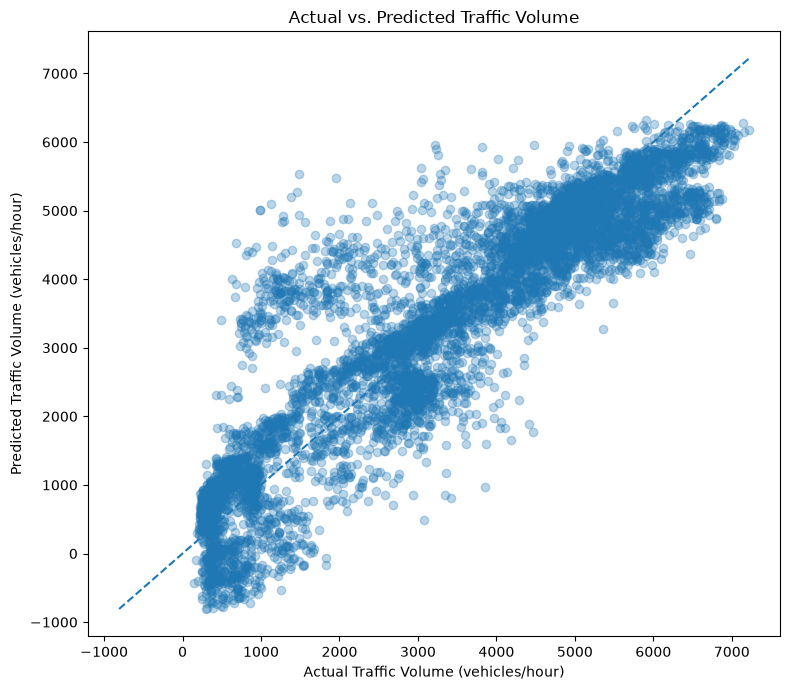

In [15]:
# Tao bang ket qua de tien kiem tra va xuat du lieu
results_df = test_df[["date_time"]].reset_index(drop=True).copy()

results_df["actual"] = y_test.reset_index(drop=True)
results_df["predicted"] = y_pred
results_df["residual"] = (
    results_df["actual"] - results_df["predicted"]
)

plt.figure(figsize=(8, 7))

plt.scatter(
    results_df["actual"],
    results_df["predicted"],
    alpha=0.3
)

# Duong du doan hoan hao: predicted = actual
lower = min(
    results_df["actual"].min(),
    results_df["predicted"].min()
)

upper = max(
    results_df["actual"].max(),
    results_df["predicted"].max()
)

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

plt.xlabel("Actual Traffic Volume (vehicles/hour)")
plt.ylabel("Predicted Traffic Volume (vehicles/hour)")
plt.title("Actual vs. Predicted Traffic Volume")
plt.tight_layout()
plt.savefig(FIG / "actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

## 14. Vẽ biểu đồ phần dư (Residual Plot)

Tính phần dư theo công thức:

$
\text{Residual}=\text{Actual}-\text{Predicted}
$

Vẽ phần dư theo giá trị dự đoán và thêm đường tham chiếu tại 0. Biểu đồ giúp kiểm tra phần dư phân bố như thế nào, có xu hướng rõ rệt hoặc độ phân tán thay đổi theo giá trị dự đoán hay không.

Nếu phần dư có cấu trúc rõ ràng thay vì phân bố tương đối ngẫu nhiên quanh 0, mô hình có thể chưa mô tả đầy đủ mối quan hệ trong dữ liệu.

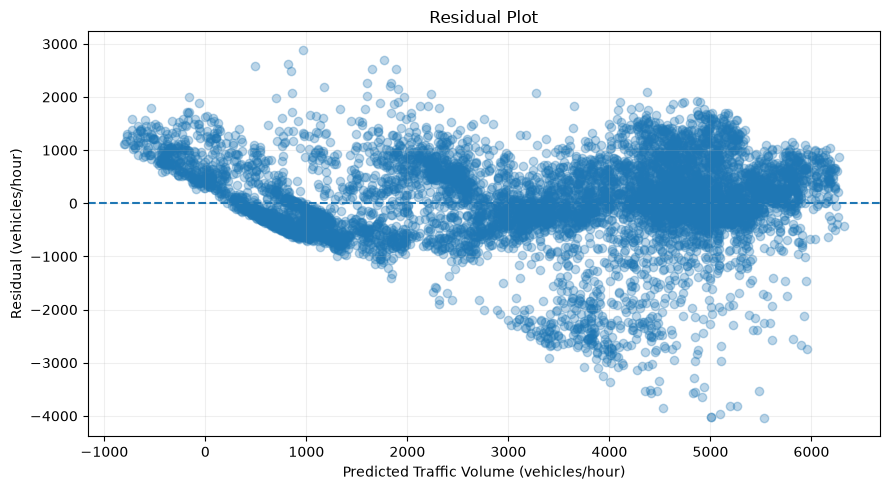

Thong ke phan du:
Thong ke phan du:
Trung bình: 17.137784339799257
Độ lệch chuẩn: 793.3239671576706
Sai số tuyệt đối trung bình: 573.0202008520396
Trung bình phần dư: 17.138
Độ lệch chuẩn phần dư: 793.324
Lưu ý: phần dư có xu hướng hoặc độ phân tán thay đổi theo giá trị dự đoán có thể cho thấy mô hình chưa mô tả hết cấu trúc dữ liệu.


In [16]:
plt.figure(figsize=(9, 5))
plt.scatter(results_df["predicted"], results_df["residual"], alpha=0.3)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted Traffic Volume (vehicles/hour)")
plt.ylabel("Residual (vehicles/hour)")
plt.title("Residual Plot")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIG / "Residual.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Thong ke phan du:")
print("Thong ke phan du:")
print("Trung bình:", results_df["residual"].mean())
print("Độ lệch chuẩn:", results_df["residual"].std())
print("Sai số tuyệt đối trung bình:", results_df["residual"].abs().mean())
print("Trung bình phần dư:", round(results_df["residual"].mean(), 3))
print("Độ lệch chuẩn phần dư:", round(results_df["residual"].std(), 3))
print("Lưu ý: phần dư có xu hướng hoặc độ phân tán thay đổi theo giá trị dự đoán có thể cho thấy mô hình chưa mô tả hết cấu trúc dữ liệu.")

## 15. Thống kê phần dư

Tính trung bình, độ lệch chuẩn, giá trị nhỏ nhất, giá trị lớn nhất và MAE từ phần dư. Đồng thời, đếm số trường hợp mô hình dự đoán thấp hơn, cao hơn hoặc bằng giá trị thực tế.

Với quy ước phần dư bằng giá trị thực tế trừ giá trị dự đoán, phần dư dương biểu thị dự đoán thấp hơn thực tế; phần dư âm biểu thị dự đoán cao hơn thực tế. Các thống kê này bổ sung thông tin định lượng cho biểu đồ phần dư.

In [17]:
# Phan tich phan du tren tap test
residual_mean = results_df["residual"].mean()
residual_std = results_df["residual"].std()
residual_min = results_df["residual"].min()
residual_max = results_df["residual"].max()
residual_mae = results_df["residual"].abs().mean()

print(f"Trung binh phan du: {residual_mean:.3f}")
print(f"Do lech chuan phan du: {residual_std:.3f}")
print(f"Phan du nho nhat: {residual_min:.3f}")
print(f"Phan du lon nhat: {residual_max:.3f}")
print(f"MAE tu phan du: {residual_mae:.3f}")

# Dem so lan du doan thap hon hoac cao hon thuc te
underestimated = (results_df["residual"] > 0).sum()
overestimated = (results_df["residual"] < 0).sum()
equal_prediction = (results_df["residual"] == 0).sum()

print(f"Du doan thap hon thuc te: {underestimated}")
print(f"Du doan cao hon thuc te: {overestimated}")
print(f"Du doan bang thuc te: {equal_prediction}")

Trung binh phan du: 17.138
Do lech chuan phan du: 793.324
Phan du nho nhat: -4040.978
Phan du lon nhat: 2888.709
MAE tu phan du: 573.020
Du doan thap hon thuc te: 4104
Du doan cao hon thuc te: 4011
Du doan bang thuc te: 0


## 16. So sánh dự đoán theo thời gian

Chọn 300 quan sát đầu tiên trong tập test theo thứ tự thời gian, sau đó vẽ hai đường biểu diễn giá trị thực tế và giá trị dự đoán.

Biểu đồ giúp quan sát mô hình có theo kịp xu hướng biến động lưu lượng giao thông hay không, đặc biệt ở các thời điểm lưu lượng tăng hoặc giảm mạnh.

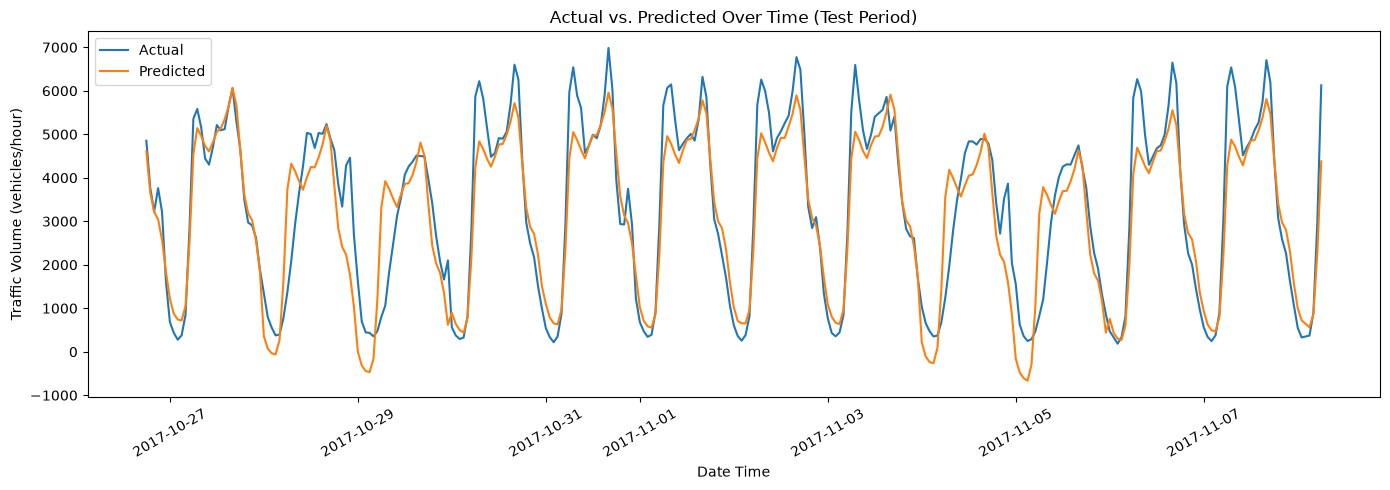

In [18]:
# Lay 300 quan sat dau tien cua test, theo thu tu thoi gian
plot_df = results_df.head(300)

plt.figure(figsize=(14, 5))

plt.plot(
    plot_df["date_time"],
    plot_df["actual"],
    label="Actual"
)

plt.plot(
    plot_df["date_time"],
    plot_df["predicted"],
    label="Predicted"
)

plt.xlabel("Date Time")
plt.ylabel("Traffic Volume (vehicles/hour)")
plt.title("Actual vs. Predicted Over Time (Test Period)")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(FIG / "actual_vs_predicted_Over_Time.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

## 17. Phân tích sai số theo nhóm dự đoán

Chia các giá trị dự đoán thành tối đa năm nhóm theo phân vị. Với mỗi nhóm, tính lưu lượng thực tế trung bình, giá trị dự đoán trung bình, MAE, phần dư trung bình và số lượng quan sát.

Phân tích này giúp xác định mô hình hoạt động khác nhau như thế nào ở các mức lưu lượng giao thông thấp, trung bình và cao. Bảng kết quả được lưu thành file CSV để sử dụng trong báo cáo.

In [19]:
# Chia du doan thanh cac nhom de kiem tra sai so
results_df["prediction_group"] = pd.qcut(
    results_df["predicted"],
    q=5,
    duplicates="drop"
)

error_summary = results_df.groupby(
    "prediction_group",
    observed=True
).agg(
    actual_mean=("actual", "mean"),
    predicted_mean=("predicted", "mean"),
    mae=("residual", lambda x: x.abs().mean()),
    mean_residual=("residual", "mean"),
    count=("residual", "size")
).reset_index()

display(error_summary.round(2))
error_summary.to_csv(
    TABLE_DIR / "prediction_error_summary.csv",
    index=False
)

,prediction_group,actual_mean,predicted_mean,mae,mean_residual,count
0,"(-808.899, 1137.844]",611.29,508.43,499.39,102.86,1623
1,"(1137.844, 3062.479]",2166.81,2141.98,592.16,24.83,1623
2,"(3062.479, 4361.637]",3439.12,3750.38,719.99,-311.27,1623
3,"(4361.637, 4951.197]",4775.09,4668.69,541.19,106.40,1623
4,"(4951.197, 6322.044]",5555.50,5392.64,512.37,162.86,1623


## 18. Phân tích hệ số hồi quy

Trích xuất tên đặc trưng sau tiền xử lý và hệ số hồi quy của mô hình. Hiển thị 15 đặc trưng có trị tuyệt đối của hệ số lớn nhất cùng hệ số chặn.

Hệ số dương hoặc âm thể hiện hướng thay đổi của giá trị dự đoán khi đặc trưng thay đổi, trong điều kiện các đặc trưng khác không đổi. Đối với biến phân loại đã mã hóa One-Hot, hệ số được diễn giải tương đối với nhóm tham chiếu. Không nên so sánh trực tiếp độ lớn hệ số giữa các biến có đơn vị khác nhau để kết luận mức độ quan trọng.

In [20]:
# Lay ten dac trung sau tien xu ly va ma hoa One-Hot
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
coefficients = model.named_steps["regressor"].coef_

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})
coef_df["Absolute_coefficient"] = coef_df["Coefficient"].abs()

print("Intercept:", round(model.named_steps["regressor"].intercept_, 3))
display(coef_df.sort_values("Absolute_coefficient", ascending=False).head(15).round(3))

print("Cách đọc: hệ số dương/âm thể hiện hướng thay đổi dự đoán khi biến thay đổi, trong điều kiện các biến khác giữ nguyên.")
print("Với biến phân loại đã One-Hot Encoding, hệ số được so sánh với nhóm tham chiếu bị loại bởi drop='first'.")
print("Không nên so sánh trực tiếp độ lớn hệ số giữa các biến có đơn vị đo khác nhau để kết luận biến nào quan trọng nhất.")

Intercept: -1137.435


,Feature,Coefficient,Absolute_coefficient
11,categorical__hour_16,4813.114,4813.114
12,categorical__hour_17,4481.770,4481.770
10,categorical__hour_15,4386.044,4386.044
9,categorical__hour_14,4094.473,4094.473
24,categorical__hour_7,3953.852,3953.852
8,categorical__hour_13,3881.090,3881.090
7,categorical__hour_12,3871.075,3871.075
25,categorical__hour_8,3774.927,3774.927
6,categorical__hour_11,3634.717,3634.717
26,categorical__hour_9,3547.197,3547.197


Cách đọc: hệ số dương/âm thể hiện hướng thay đổi dự đoán khi biến thay đổi, trong điều kiện các biến khác giữ nguyên.
Với biến phân loại đã One-Hot Encoding, hệ số được so sánh với nhóm tham chiếu bị loại bởi drop='first'.
Không nên so sánh trực tiếp độ lớn hệ số giữa các biến có đơn vị đo khác nhau để kết luận biến nào quan trọng nhất.


## 12. Lưu ý khi diễn giải kết quả

Mô hình được đánh giá trên 20% dữ liệu ở giai đoạn thời gian cuối, không phải chia ngẫu nhiên. Kết quả chỉ phản ánh hiệu năng trên giai đoạn test này. Vì dữ liệu giao thông theo giờ có thể phụ thuộc thời gian và có những biến động theo mùa/ngày/giờ, không diễn giải hệ số hồi quy như bằng chứng nhân quả.

# 13. Lưu bảng kết quả

In [21]:

# Luu cac bang ket qua
comparison.to_csv(
    TABLE_DIR / "regression_model_comparison.csv",
    index=False
)

results_df.to_csv(
    TABLE_DIR / "regression_test_predictions.csv",
    index=False
)

coef_df.to_csv(
    TABLE_DIR / "regression_coefficients.csv",
    index=False
)

print("Da luu cac bang ket qua tai:", TABLE_DIR.resolve())

Da luu cac bang ket qua tai: C:\Users\PHUONG NHI\Downloads\524H0185_524H0073_524H0175\outputs\03_Multiple_Linear_Regression\tables


## Kết luận và đánh giá mô hình

Mô hình Hồi quy tuyến tính đa biến được xây dựng để dự đoán lưu lượng giao thông (traffic_volume) dựa trên các đặc trưng về thời tiết và thời gian.

Trên tập kiểm tra, mô hình đạt MAE = 573,02, RMSE = 793,46 và R² = 0,8378. So với Baseline, MAE giảm 66,8% và RMSE giảm 59,7%, cho thấy hiệu quả dự đoán được cải thiện đáng kể.

Các biểu đồ giúp đánh giá mức độ phù hợp giữa giá trị thực tế và dự đoán, phân tích sai số và theo dõi biến động lưu lượng theo thời gian. Tuy nhiên, mô hình vẫn có thể dự đoán chưa chính xác khi lưu lượng biến động đột ngột hoặc xuất hiện điều kiện bất thường.

Nhìn chung, mô hình cho kết quả khả quan. Có thể cải thiện thêm bằng cách xây dựng đặc trưng mới hoặc thử nghiệm mô hình khác, đồng thời giữ nguyên tập kiểm tra theo thời gian để so sánh công bằng.